In [ ]:
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'heliomind-integrated').is_dir())
(ROOT/'data/processed/Anomaly').mkdir(parents=True,exist_ok=True)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pvlib

# Feature Engineering

This notebook creates features for two machine-learning tasks:

1. Solar-power forecasting.
2. Solar-inverter anomaly detection.

The processed datasets are used as inputs, and final feature datasets are saved in the `data/processed` folder.

## 1. Forecasting features

Load the cleaned DKASC forecast data and create:

- Hour, month, and day-of-week features.

- Solar zenith and elevation features.**Output:** `forecast_features_final.csv`

- 1-hour, 24-hour, and rolling production features.

In [ ]:
PROCESSED_DIR = str(ROOT / 'data/processed/Forecast')
clean_path = os.path.join(PROCESSED_DIR, 'forecast_dkasc_clean.csv')
output_path = os.path.join(PROCESSED_DIR, 'forecast_features_final.csv')

print("Loading cleaned forecast data...")
df = pd.read_csv(clean_path)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

print("Adding time features...")
df['hour'] = df['timestamp'].dt.hour
df['month'] = df['timestamp'].dt.month
df['day_of_week'] = df['timestamp'].dt.dayofweek

print("Adding solar position features...")
site = pvlib.location.Location(-23.76, 133.87, tz='Australia/Darwin')
solar_position = site.get_solarposition(df['timestamp'])
df['solar_zenith'] = solar_position['zenith'].values
df['solar_elevation'] = solar_position['elevation'].values

print("Adding lag and rolling features...")
df['power_lag_1h'] = df['actual_power_kw'].shift(12).fillna(0)
df['power_lag_24h'] = df['actual_power_kw'].shift(288).fillna(0)
df['power_roll_mean_1h'] = df['actual_power_kw'].rolling(window=12).mean().fillna(0)

df.to_csv(output_path, index=False)
print(f"\nFeature engineering completed. Number of rows: {len(df)}")
print(f"Saved file: {output_path}")
print("\nSample of the final dataset:")
print(df[['timestamp', 'actual_power_kw', 'ghi', 'solar_zenith', 'power_lag_1h']].head())

Loading cleaned forecast data...
Adding time features...
Adding solar position features...
Adding lag and rolling features...

Feature engineering completed. Number of rows: 98146
Saved file: F:\Abdelrahman1\ME\programming\SIC\Project3.2\data\processed\Forecast\forecast_features_final.csv

Sample of the final dataset:
            timestamp  actual_power_kw       ghi  solar_zenith  power_lag_1h
0 2025-01-01 00:00:00              0.0  2.122361     42.939074           0.0
1 2025-01-01 00:05:00              0.0  2.309545     41.808503           0.0
2 2025-01-01 00:10:00              0.0  2.226635     40.676999           0.0
3 2025-01-01 00:15:00              0.0  2.177083     39.544599           0.0
4 2025-01-01 00:20:00              0.0  2.419703     38.411337           0.0


## 2. Kaggle anomaly features

Load the labeled Kaggle dataset and create:

- Hour and day-of-week features.

- Relative inverter power ratio.**Output:** `anomaly_features_final.csv`

- Actual-minus-expected power residual.
- Previous 1-step and 4-step inverter power values.

In [ ]:
PROCESSED_DIR = str(ROOT / 'data/processed/Anomaly')
input_path = os.path.join(PROCESSED_DIR, 'kaggle_anomaly_data.csv')
output_path = os.path.join(PROCESSED_DIR, 'anomaly_features_final.csv')

print("Loading anomaly data...")
df = pd.read_csv(input_path)
df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'])

df = df.sort_values(['SOURCE_KEY', 'DATE_TIME']).reset_index(drop=True)

print("Adding time features...")
df['hour'] = df['DATE_TIME'].dt.hour
df['day_of_week'] = df['DATE_TIME'].dt.dayofweek

print("Calculating inverter production ratio...")
plant_avg_power = df.groupby('DATE_TIME')['AC_POWER'].transform('mean')
df['inverter_ratio'] = df['AC_POWER'] / (plant_avg_power + 1e-5)

print("Calculating actual versus expected power residual...")
expected_power = df.groupby('IRRADIATION')['AC_POWER'].transform('median')
df['residual'] = df['AC_POWER'] - expected_power

print("Adding inverter lag features...")
df['power_lag_1'] = df.groupby('SOURCE_KEY')['AC_POWER'].shift(1)
df['power_lag_4'] = df.groupby('SOURCE_KEY')['AC_POWER'].shift(4)
df[['power_lag_1', 'power_lag_4']] = df[['power_lag_1', 'power_lag_4']].fillna(0)

df = df.dropna(subset=['inverter_ratio', 'residual'])

cols_to_drop = ['SOURCE_KEY_weather', 'DAILY_YIELD', 'TOTAL_YIELD', 'PLANT_ID']
df = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

print(f"\nFeature engineering completed. Number of rows: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print("\nSample of the new data:")
print(df[['DATE_TIME', 'SOURCE_KEY', 'AC_POWER', 'inverter_ratio', 'residual', 'is_anomaly']].head(10))

df.to_csv(output_path, index=False)
print(f"\nSaved the model-ready anomaly data to: {output_path}")

-----------------------------------------

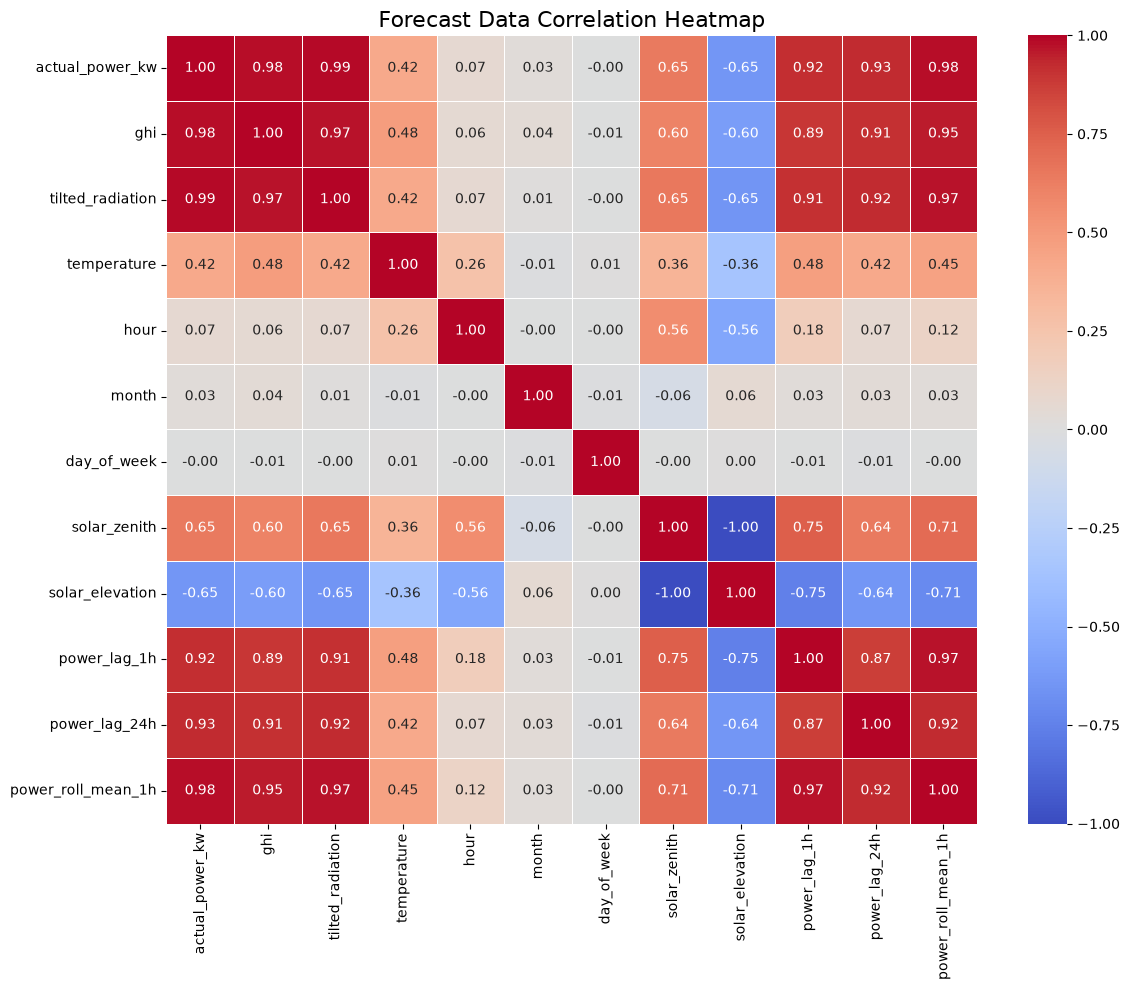

In [10]:
PROCESSED_DIR = str(ROOT / 'data/processed/Forecast')
input_path = os.path.join(PROCESSED_DIR, 'forecast_features_final.csv')

df = pd.read_csv(input_path)

numeric_df = df.select_dtypes(include=['float64', 'int64'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title('Forecast Data Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

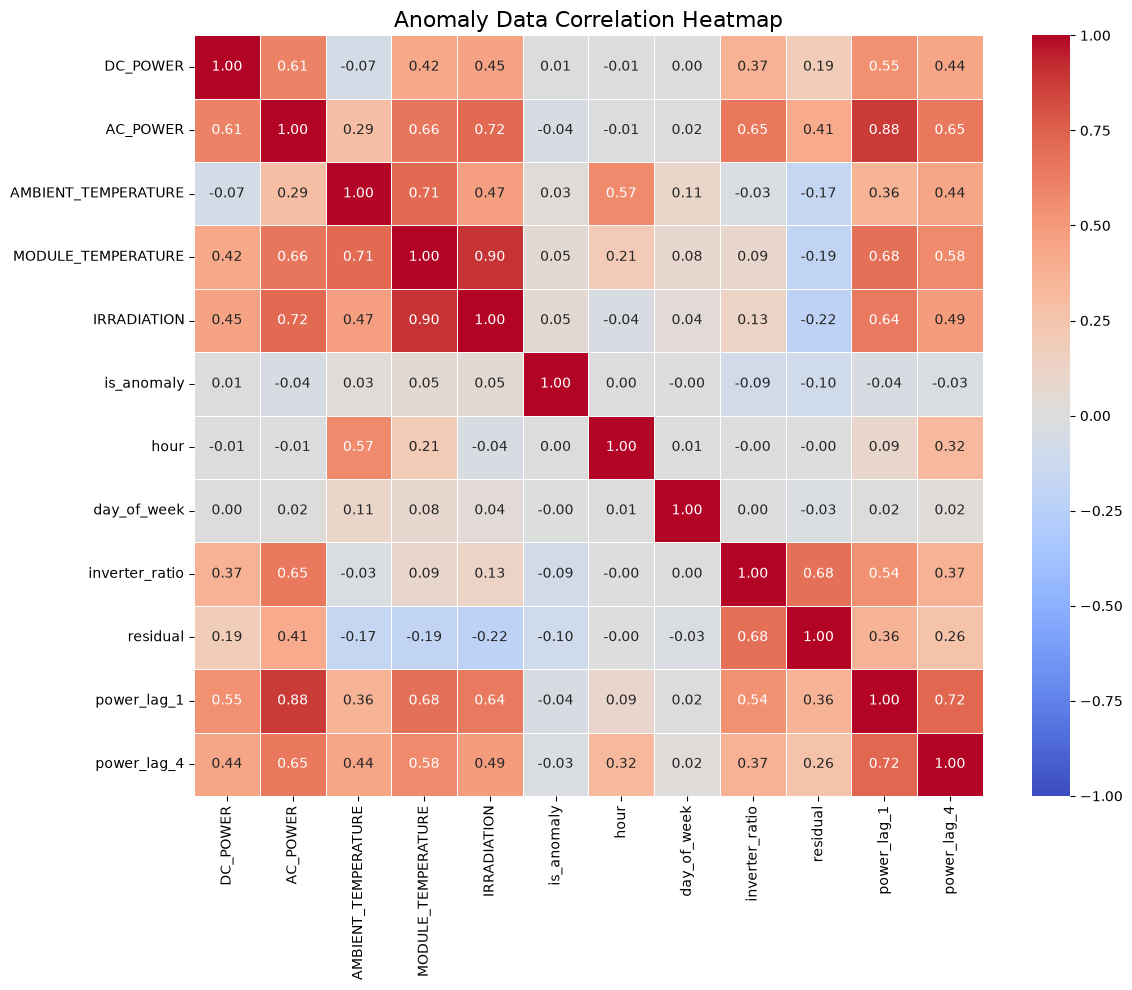

In [12]:
PROCESSED_DIR = str(ROOT / 'data/processed/Anomaly')
input_path = os.path.join(PROCESSED_DIR, 'anomaly_features_final.csv')

df = pd.read_csv(input_path)

numeric_df = df.select_dtypes(include=['float64', 'int64'])

corr_matrix = numeric_df.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, vmax=1, 
    linewidths=0.5
)
plt.title('Anomaly Data Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

## Forecast and Anomaly EDA Questions and Answers

### Forecasting dataset

**Question 1: Which features have the strongest relationship with actual solar power?**

**Answer:** Global horizontal irradiance (`ghi`), tilted radiation, and the rolling and lagged production features have strong positive correlations with `actual_power_kw`. The calculated correlations are approximately `0.980` for `ghi`, `0.990` for `tilted_radiation`, `0.977` for `power_roll_mean_1h`, `0.925` for `power_lag_24h`, and `0.915` for `power_lag_1h`.

**Conclusion:** Solar irradiance and recent production history explain much of the output variation, so they are important forecasting features. Tilted radiation and GHI are also highly related to each other.

**Question 2: Do some forecast features provide overlapping information?**

**Answer:** Yes. `ghi` and `tilted_radiation` measure related forms of solar radiation and both have very strong correlations with actual power. `actual_power_kw`, the rolling mean, and lag features are also closely related because they represent the same production signal at different time scales.

**Conclusion:** The model may benefit from correlation-aware feature selection or regularization to reduce redundant information and multicollinearity.

**Question 3: Do time-history features improve the forecast signal?**

**Answer:** Yes. Both `power_lag_1h` and `power_lag_24h` have strong positive correlations with current production. The rolling one-hour mean has an even stronger correlation.

**Conclusion:** Lag and rolling features capture short-term behavior and repeated daily production patterns, so they should be retained for evaluation.

### Anomaly dataset

**Question 4: Does inverter_ratio decrease for anomalous observations?**

**Answer:** Yes. The mean inverter ratio is approximately `1.00` for normal observations and `0.49` for anomalous observations. Its correlation with `is_anomaly` is approximately `-0.092`, so it separates the groups clearly in the mean values but has a modest correlation at the row level.

**Conclusion:** `inverter_ratio` is useful, but it should not be described as a strongly correlated feature by itself.

**Question 5: Does residual distinguish anomalies from normal observations?**

**Answer:** Anomalous observations have a much more negative mean residual than normal observations: approximately `-393` compared with `-46`. The correlation with `is_anomaly` is approximately `-0.095`.

**Conclusion:** Residual is useful because anomalies generally produce less power than expected. Its modest correlation also means it should be combined with other features rather than used alone.

**Question 6: Which anomaly features are the most useful based on the heatmap?**

**Answer:** In the current feature file, `residual` has the strongest absolute correlation with `is_anomaly` at approximately `0.095`, followed closely by `inverter_ratio` at approximately `0.092`. `AC_POWER` and lag features also provide weaker relationships.

**Conclusion:** The heatmap supports keeping `inverter_ratio` and `residual`, but the model should be evaluated with additional metrics such as precision, recall, F1-score, and the confusion matrix.